# Régularité des TGV : compréhension et qualité des données

Ce notebook prépare l'étude de la fiabilité des liaisons TGV. Il comporte quatre étapes :
1. situer le contexte avec la régularité nationale des TGV depuis 2015 ;
2. découvrir le jeu de données détaillé par liaison, sur lequel porte toute l'étude ;
3. établir un diagnostic de la qualité de ces données ;
4. fixer les règles de nettoyage, puis les appliquer.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from projet_sncf.business.prevision.diagnostic import (
    CLE_SANS_SERVICE,
    chercher_doublons,
    compter_inclusions,
    compter_valeurs_manquantes,
    masques_valeurs_impossibles,
    negatifs_par_annee,
    tableau_controles,
    verifier_apres_nettoyage,
)
from projet_sncf.business.prevision.exploration import (
    circulations_par_annee,
    comparer_periodes,
    moyennes_par_periode,
    retards_par_cause,
)
from projet_sncf.database.nettoyage import COLONNES_COMMENTAIRES, nettoyer
from projet_sncf.utils.graphiques import (
    tracer_avant_apres,
    tracer_barres,
    tracer_evolution,
)

dossier_donnees = os.path.join("..", "data")

In [2]:
from projet_sncf.utils.logging_config import setup_logging

chemin_logs = setup_logging(log_dir=os.path.join("..", "logs"), console=False)
print("Logs écrits dans :", chemin_logs)

Logs écrits dans : ../logs/sncf.log


## 1. Contexte national

### 1.1 Chargement

In [3]:
data_regularite = pd.read_excel(
    os.path.join(dossier_donnees, "reglarite-mensuelle-tgv-nationale.xlsx")
)
data_regularite.head(10)

,Date,Régularité composite,Ponctualité origine
0,2015-01,91.627358,85.280538
1,2015-02,90.325652,84.248184
2,2015-03,93.421794,87.453249
3,2015-04,90.801173,85.342175
4,2015-05,91.373510,85.048795
5,2015-06,87.697086,82.612883
6,2015-07,84.887154,79.819406
7,2015-08,89.102128,82.234832
8,2015-09,89.545803,84.638101
9,2015-10,91.013911,85.124313


In [4]:
data_regularite.info()

<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  138 non-null    str    
 1   Régularité composite  138 non-null    float64
 2   Ponctualité origine   138 non-null    float64
dtypes: float64(2), str(1)
memory usage: 4.3 KB


### 1.2 Qualité du fichier national

In [5]:
print("Valeurs manquantes :", data_regularite.isna().sum().sum())
print("Lignes en double :", data_regularite.duplicated().sum())
print("Mois en double :", data_regularite["Date"].duplicated().sum())
print(
    "Période :",
    data_regularite["Date"].min(),
    "→",
    data_regularite["Date"].max(),
)

Valeurs manquantes : 0
Lignes en double : 0
Mois en double : 0
Période : 2015-01 → 2026-06


### 1.3 Description

In [6]:
variables_descr = ["Régularité composite", "Ponctualité origine"]
data_regularite[variables_descr].describe()

,Régularité composite,Ponctualité origine
count,138.000000,138.000000
mean,88.685763,83.137958
std,2.931835,3.376082
min,77.851061,72.269528
25%,87.000754,81.296658
50%,89.075756,83.413237
75%,90.743996,85.266584
max,94.559508,90.732140


Ce fichier provient de l'open data de la SNCF. Il comporte **138** observations mensuelles, de janvier 2015 à
juin 2026, sur **3** variables :
- **Date** : le mois et l'année d'observation ;
- **Régularité composite** : le pourcentage de trains arrivés à l'heure à leur gare de destination ;
- **Ponctualité origine** : le pourcentage de trains partis à l'heure de leur gare de départ.

« À l'heure » ne signifie pas sans aucun retard, mais dans un délai jugé acceptable selon la durée du trajet
(5, 10 ou 15 minutes de tolérance).

Selon les mois, entre 72 % et 91 % des trains partent à l'heure, et entre 78 % et 95 % arrivent à l'heure. En
moyenne, 88,7 % des trains arrivent à l'heure et 83,1 % partent à l'heure. Le fichier ne contient ni valeur
manquante ni mois en double.

### 1.4 Évolution dans le temps

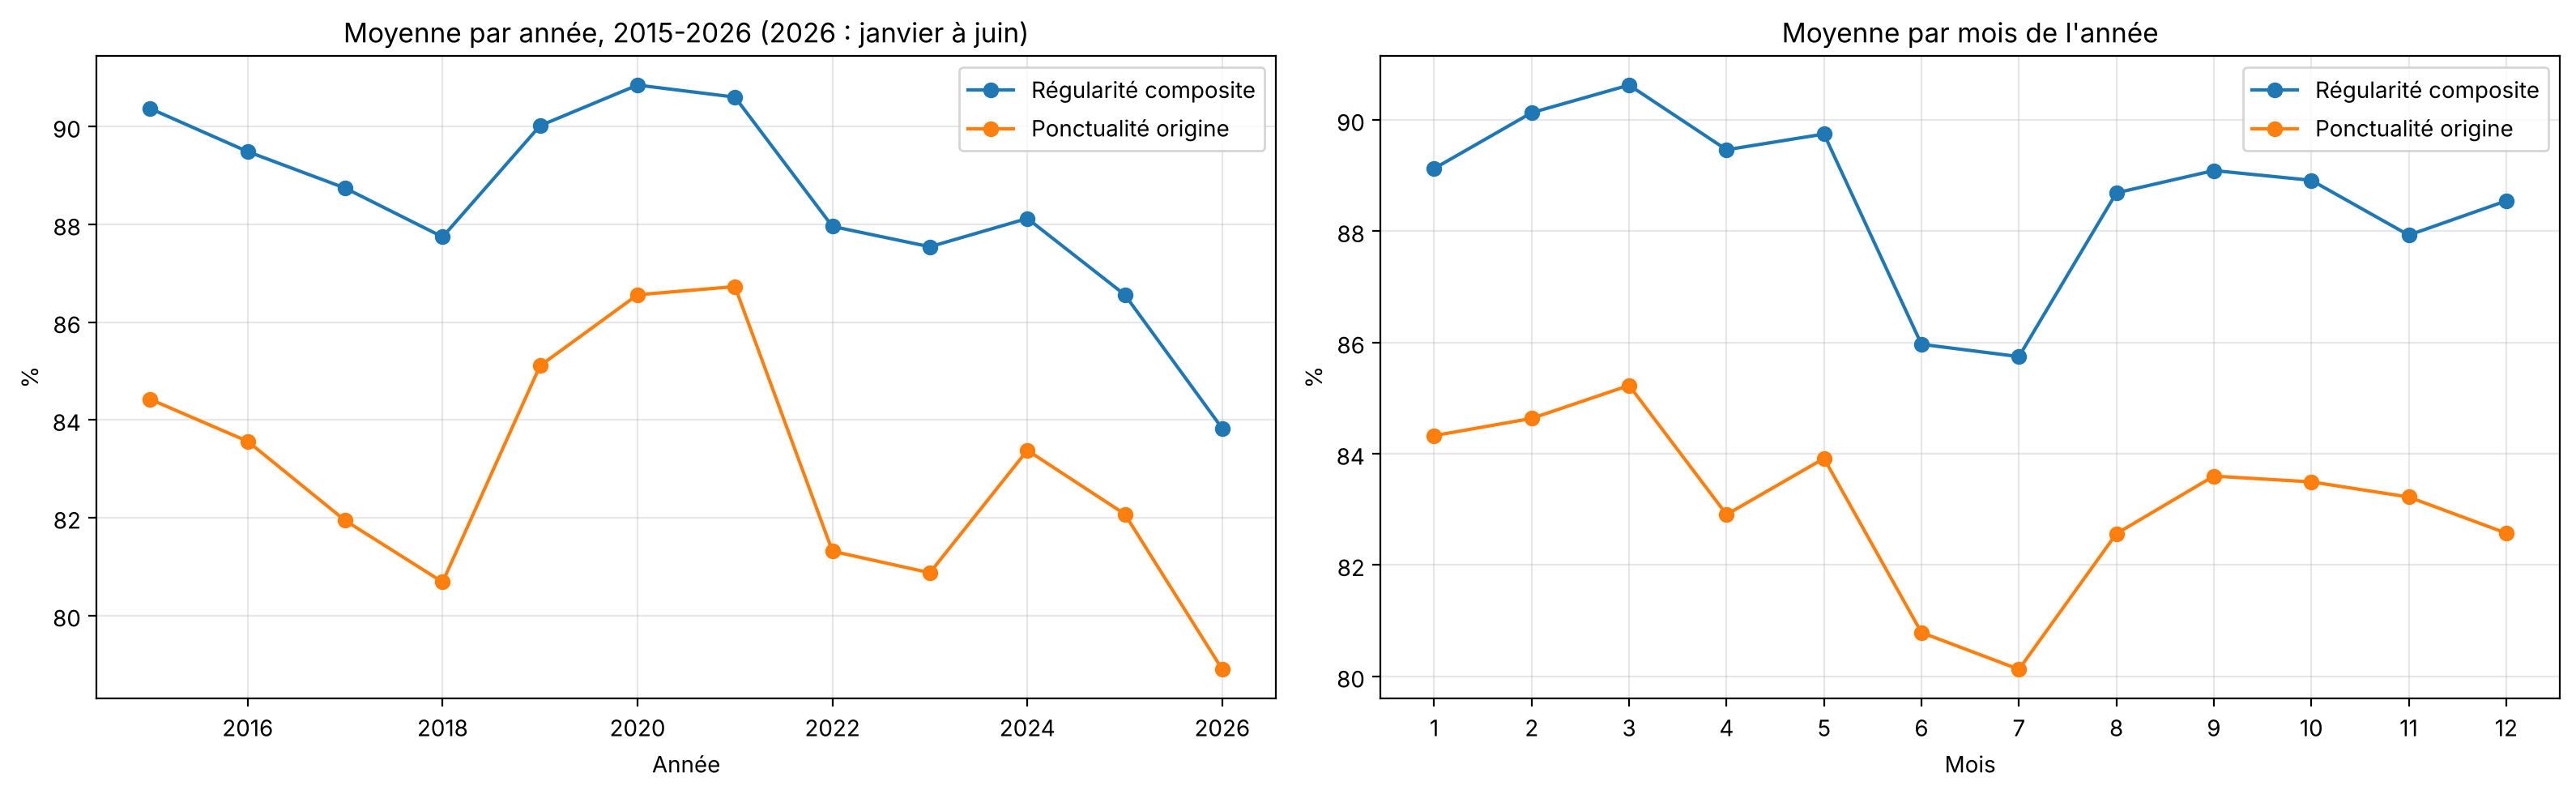

In [7]:
regularite_annee, regularite_mois = moyennes_par_periode(
    data_regularite, variables_descr
)

fig = tracer_evolution(
    regularite_annee,
    regularite_mois,
    variables_descr,
    titre_annee="Moyenne par année, 2015-2026 (2026 : janvier à juin)",
)
plt.show()

In [8]:
display(regularite_annee.round(2))
display(regularite_mois.round(2))

,Année,Régularité composite,Ponctualité origine
0,2015,90.37,84.42
1,2016,89.49,83.56
2,2017,88.74,81.94
3,2018,87.74,80.68
4,2019,90.02,85.11
5,2020,90.85,86.56
6,2021,90.60,86.73
7,2022,87.96,81.31
8,2023,87.54,80.87
9,2024,88.12,83.38


,Mois,Régularité composite,Ponctualité origine
0,1,89.13,84.33
1,2,90.13,84.64
2,3,90.62,85.23
3,4,89.46,82.91
4,5,89.74,83.92
5,6,85.97,80.79
6,7,85.75,80.13
7,8,88.69,82.56
8,9,89.09,83.60
9,10,88.91,83.50


**Lecture des graphiques**

- **Par année**, l'évolution se fait en trois phases plutôt qu'en ligne droite. De 2015 à 2018, la régularité
  baisse jusqu'à un creux en 2018 (87,7 %). De 2019 à 2021, elle remonte, avec un point haut en 2020 (90,9 %). À
  partir de 2022, elle rechute (88,0 %) et continue de se dégrader jusqu'en 2026 (83,8 %). La valeur de 2026 ne
  porte que sur janvier à juin, dont juin, le pire mois de toute la série : elle n'est pas directement comparable
  aux années complètes.
- Le point haut de 2020-2021 ne traduit pas une amélioration du service : il coïncide avec la pandémie de
  Covid-19, pendant laquelle il y a eu beaucoup moins de trains. Moins de circulations, c'est mécaniquement moins
  de risques de retard. La section 2.4 vérifie ce point avec le nombre de trains prévus.
- **Par mois**, juin et juillet sont nettement les moins bons (environ 86 %), et mars est le meilleur (90,6 %).
  Deux explications viennent naturellement à l'esprit : les travaux d'été sur les voies, et l'affluence des
  vacances. 

## 2. Le jeu de données détaillé par liaison


### 2.1 Chargement

In [9]:
data = pd.read_csv(
    os.path.join(dossier_donnees, "regularite-mensuelle-tgv-aqst.csv"), sep=";"
)
data.head(10)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386
5,2018-01,National,ST MALO,PARIS MONTPARNASSE,158,92,0,NaN,2,1.225000,...,6,4.763978,3,1,22.222222,66.666667,0.000000,11.111111,0.000000,0.000000
6,2018-01,National,TOULOUSE MATABIAU,PARIS MONTPARNASSE,257,184,0,NaN,23,11.221739,...,26,7.510507,12,3,59.090909,22.727273,4.545455,9.090909,4.545455,0.000000
7,2018-01,National,VANNES,PARIS MONTPARNASSE,156,278,1,NaN,168,5.120437,...,25,6.241487,11,3,24.137931,44.827586,20.689655,3.448276,3.448276,3.448276
8,2018-01,National,REIMS,PARIS EST,46,230,1,NaN,93,7.432796,...,20,3.538937,3,0,17.948718,41.025641,20.512821,5.128205,0.000000,15.384615
9,2018-01,National,DOUAI,PARIS NORD,77,197,3,NaN,39,8.032906,...,10,5.046907,5,3,36.363636,18.181818,22.727273,18.181818,4.545455,0.000000


In [10]:
print(data.columns.tolist())

['Date', 'Service', 'Gare de départ', "Gare d'arrivée", 'Durée moyenne du trajet', 'Nombre de circulations prévues', 'Nombre de trains annulés', 'Commentaire annulations', 'Nombre de trains en retard au départ', 'Retard moyen des trains en retard au départ', 'Retard moyen de tous les trains au départ', 'Commentaire retards au départ', "Nombre de trains en retard à l'arrivée", "Retard moyen des trains en retard à l'arrivée", "Retard moyen de tous les trains à l'arrivée", "Commentaire retards à l'arrivée", 'Nombre trains en retard > 15min', 'Retard moyen trains en retard > 15 (si liaison concurrencée par vol)', 'Nombre trains en retard > 30min', 'Nombre trains en retard > 60min', 'Prct retard pour causes externes', 'Prct retard pour cause infrastructure', 'Prct retard pour cause gestion trafic', 'Prct retard pour cause matériel roulant', 'Prct retard pour cause gestion en gare et réutilisation de matériel', 'Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, corre

In [11]:
print(data.shape)
print("Période :", data["Date"].min(), "→", data["Date"].max())
data.info()

(12907, 26)
Période : 2018-01 → 2026-09
<class 'pandas.DataFrame'>
RangeIndex: 12907 entries, 0 to 12906
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12907 non-null  str    
 1   Service                                                                                      12907 non-null  str    
 2   Gare de départ                                                                               12907 non-null  str    
 3   Gare d'arrivée                                                                               12907 non-null  str    
 4   Durée moyenne du trajet                                                                      12907 non-null  int64  
 5   Nom

Le jeu de données détaille, pour chaque liaison TGV et chaque mois de janvier 2018 à septembre 2026, le nombre de trains
prévus, annulés et en retard, la durée moyenne des retards et la répartition de leurs causes. Il comporte
**12 907** observations et **26** colonnes.

### 2.2 Catégorisation des variables

| Catégorie | Variables | Description |
|---|---|---|
| **Identification** | `Date`, `Service`, `Gare de départ`, `Gare d'arrivée`, `Durée moyenne du trajet` | le contexte de chaque observation : quelle liaison, quel mois, quel type de service, et la durée du trajet |
| **Volumes** | `Nombre de circulations prévues`, `Nombre de trains annulés`, `Nombre de trains en retard au départ`, `Nombre de trains en retard à l'arrivée`, `Nombre trains en retard > 15min`, `Nombre trains en retard > 30min`, `Nombre trains en retard > 60min` | nombres de trains : circulations, annulations, retards par palier de gravité |
| **Retards (minutes)** | `Retard moyen des trains en retard au départ`, `Retard moyen de tous les trains au départ`, `Retard moyen des trains en retard à l'arrivée`, `Retard moyen de tous les trains à l'arrivée`, `Retard moyen trains en retard > 15 (si liaison concurrencée par vol)` | durées moyennes de retard, calculées soit sur les seuls trains en retard, soit sur tous les trains |
| **Causes de retard (%)** | `Prct retard pour causes externes`, `Prct retard pour cause infrastructure`, `Prct retard pour cause gestion trafic`, `Prct retard pour cause matériel roulant`, `Prct retard pour cause gestion en gare et réutilisation de matériel`, `Prct retard pour cause prise en compte voyageurs` | répartition en pourcentage des causes de retard |
| **Commentaires** | `Commentaire annulations`, `Commentaire retards au départ`, `Commentaire retards à l'arrivée` | texte libre décrivant ponctuellement des incidents |

### 2.3 Les colonnes commentaires

In [12]:
pd.DataFrame(
    {
        "valeurs différentes": data[COLONNES_COMMENTAIRES].nunique(),
        "part renseignée (%)": (
            data[COLONNES_COMMENTAIRES].notna().mean() * 100
        ).round(1),
    }
)

,valeurs différentes,part renseignée (%)
Commentaire annulations,0,0.0
Commentaire retards au départ,0,0.0
Commentaire retards à l'arrivée,302,5.4


In [13]:
data.loc[
    data["Commentaire retards à l'arrivée"].notna(),
    [
        "Date",
        "Gare de départ",
        "Gare d'arrivée",
        "Commentaire retards à l'arrivée",
    ],
].head(5)

,Date,Gare de départ,Gare d'arrivée,Commentaire retards à l'arrivée
1,2018-01,LE MANS,PARIS MONTPARNASSE,"Ce mois-ci, l'OD a été touchée par les inciden..."
6,2018-01,TOULOUSE MATABIAU,PARIS MONTPARNASSE,"Ce mois-ci, l'OD a été touchée par les inciden..."
15,2018-01,GRENOBLE,PARIS LYON,Le 9760 heurte un chevreuil vers Le-Creusot-Mo...
19,2018-01,MONTPELLIER,PARIS LYON,Heurt d’un chevreuil par OUIGO 7801 vers Valen...
20,2018-01,PARIS LYON,MARSEILLE ST CHARLES,Dérangement de commutateur sur LN1 vers Tonnerre


On remarque que les commentaires sur les annulations et sur les retards au départ sont **toujours vides** : ils
n'apportent aucune information. Les commentaires sur les retards à l'arrivée sont renseignés pour environ 5,4 % des
lignes.

Ces colonnes ne seront pas utilisées dans l'étude : ce sont des textes libres, rédigés au cas par cas, qu'on ne
peut pas comparer d'une ligne à l'autre ni intégrer à un calcul. Elles sont supprimées au nettoyage.
Les commentaires à l'arrivée restent consultables dans le fichier brut pour éclairer un cas particulier.

### 2.4 Le Covid a-t-il réduit le trafic ?

Pour vérifier l'explication du point haut de 2020 (section 1.4), on compte les circulations prévues par année.

,Nombre de circulations prévues
Année,
2018,414653
2019,378790
2020,263853
2021,383087
2022,437705
2023,445544
2024,444878
2025,437974
2026,322853


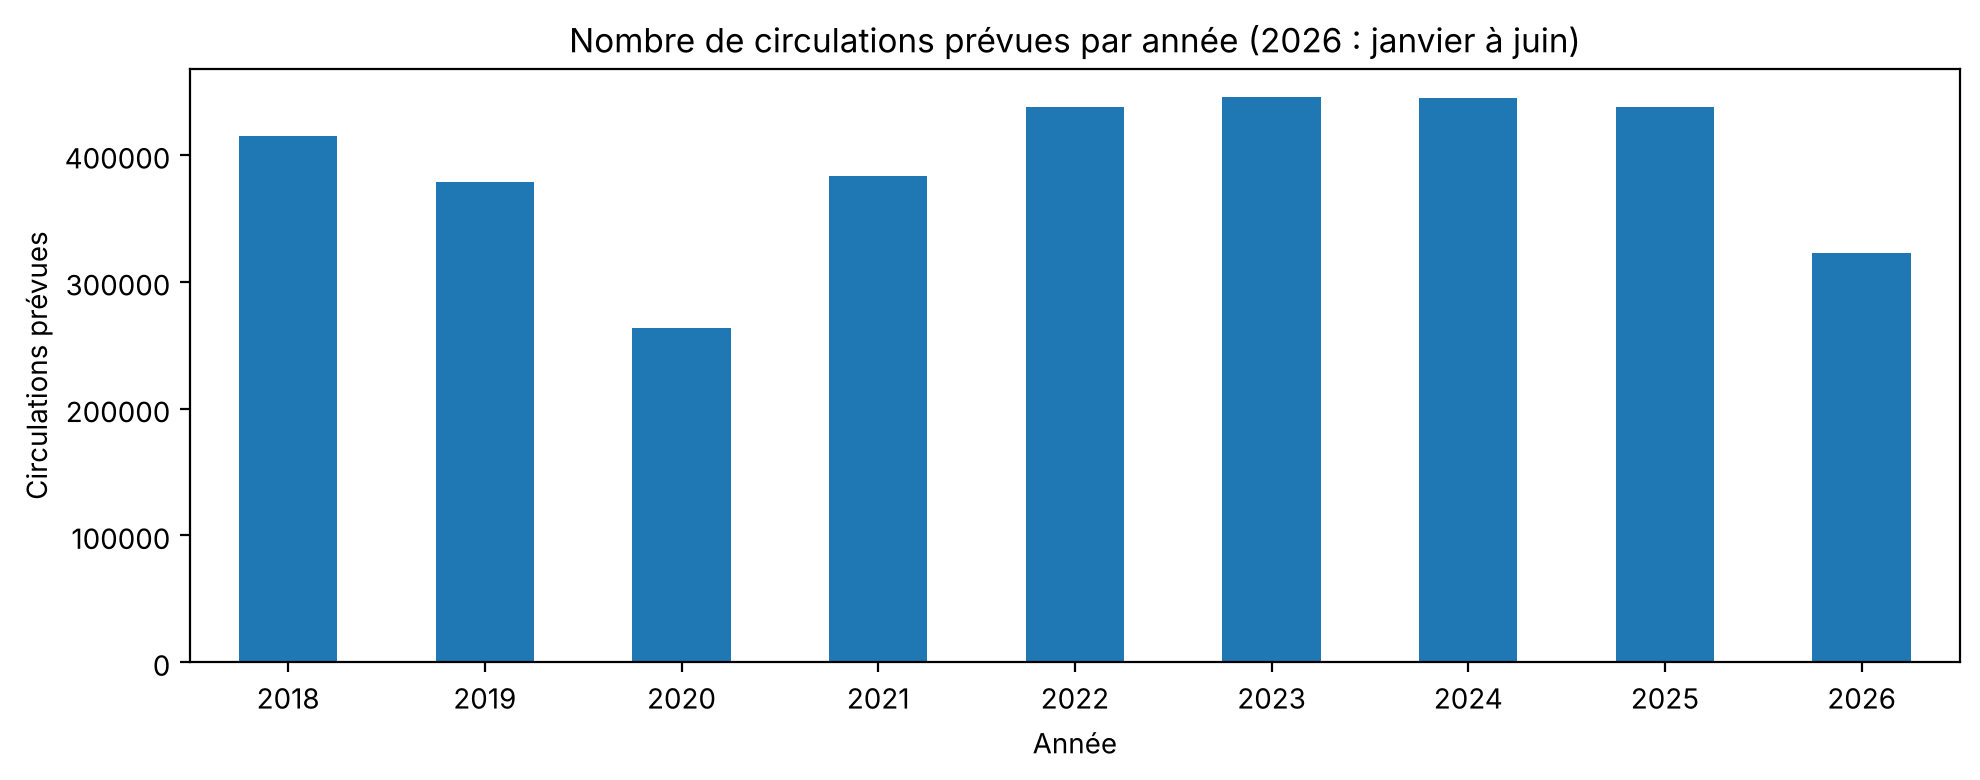

In [14]:
circulations_annee = circulations_par_annee(data)
display(circulations_annee.to_frame())

fig = tracer_barres(
    circulations_annee,
    "Nombre de circulations prévues par année (2026 : janvier à juin)",
    xlabel="Année",
    ylabel="Circulations prévues",
)
plt.show()

On remarque qu'en 2020, il y a eu environ **264 000** circulations prévues, contre 380 000 à 445 000 les autres
années complètes, soit environ un tiers de moins que les années voisines. Cela confirme que le point haut de
régularité en 2020 s'explique au moins en partie par un trafic réduit, et non par une amélioration du service.

### 2.5 Pourquoi l'été est-il plus perturbé ?

Les colonnes de causes donnent la part de chaque cause dans les retards d'un mois. En la multipliant par le nombre
de trains en retard, on obtient un **nombre de retards par cause**. On le rapporte à 100 trains prévus, pour
comparer les mois entre eux.

In [15]:
pour_100_trains = retards_par_cause(data)
display(pour_100_trains.round(2))

evolution_ete = comparer_periodes(
    pour_100_trains, mois_etudies=(6, 7), mois_reference=(3, 4)
)
display(evolution_ete.round(2).to_frame("juin-juillet / mars-avril"))

,externes,infrastructure,gestion du trafic,matériel roulant,gestion en gare,voyageurs (affluence)
Mois,,,,,,
1,3.80,3.07,2.98,2.63,1.07,0.91
2,3.28,2.81,2.86,2.30,0.83,0.84
3,2.68,2.83,2.43,2.05,0.81,0.81
4,2.47,2.77,2.55,2.12,1.04,0.99
5,2.87,2.47,2.13,2.32,1.20,1.08
6,3.39,3.62,2.85,3.17,2.01,1.23
7,4.09,3.21,3.46,3.53,2.09,1.54
8,3.12,2.44,2.86,3.06,1.52,1.44
9,2.75,2.85,2.77,2.73,1.39,1.13


,juin-juillet / mars-avril
infrastructure,1.22
gestion du trafic,1.27
externes,1.45
voyageurs (affluence),1.54
matériel roulant,1.60
gestion en gare,2.21


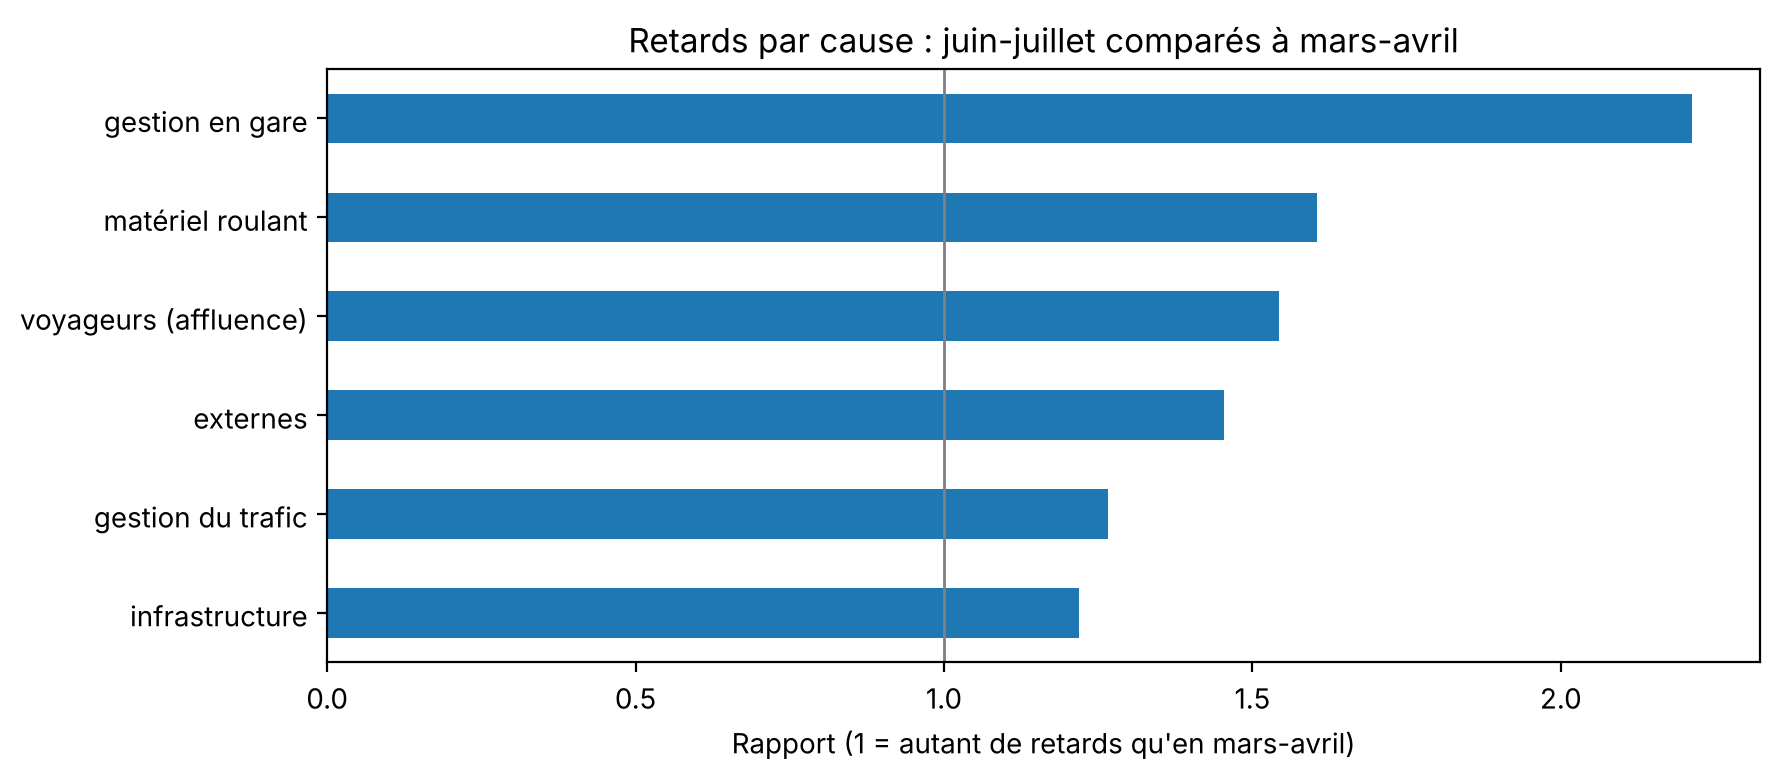

In [16]:
fig = tracer_barres(
    evolution_ete,
    "Retards par cause : juin-juillet comparés à mars-avril",
    xlabel="Rapport (1 = autant de retards qu'en mars-avril)",
    horizontal=True,
    ligne_reference=1,
    taille=(9, 4),
)
plt.show()

On remarque qu'en juin-juillet, il y a environ **45 % de retards de plus** qu'en mars-avril pour 100 trains
prévus, et que **toutes les causes** augmentent.

En revanche, l'hypothèse des **travaux d'été** n'est pas confirmée : la cause « infrastructure » est celle qui
augmente **le moins**. Les causes qui augmentent le plus sont la **gestion en gare** (plus de deux fois plus de
retards), le **matériel roulant** et la **prise en compte des voyageurs** (affluence, correspondances). L'été est
donc surtout perturbé par la charge du réseau et des gares pendant les vacances, plus que par les travaux.

Ces causes sont celles déclarées ; elles donnent une tendance, pas une explication certaine.

## 3. Diagnostic de la qualité des données

Avant d'utiliser les données, on vérifie qu'elles sont complètes, sans doublon et cohérentes. On ne corrige
rien dans cette section : les décisions sont prises en section 4.

### 3.1 Valeurs manquantes

On cherche les vraies valeurs manquantes, mais aussi les faux vides (« NA », « - », espaces…).

In [17]:
print(
    "Valeurs manquantes (hors commentaires) :",
    compter_valeurs_manquantes(data),
)

Valeurs manquantes (hors commentaires) : 0


On remarque qu'en dehors des commentaires, aucune valeur ne manque.

### 3.2 Doublons

On cherche d'abord les lignes entièrement identiques, puis les liaisons qui apparaissent deux fois le même mois.

In [18]:
resume_doublons, doublons = chercher_doublons(data)
for nom, valeur in resume_doublons.items():
    print(f"{nom} : {valeur}")

doublons[
    CLE_SANS_SERVICE + ["Service", "Nombre de circulations prévues"]
].head(6)

Lignes entièrement identiques : 0
Lignes en double sur la clé : 84
Mois concernés : ['2025-07', '2025-08', '2025-09']
Liaisons concernées : 14
Doublons si l'on ajoute le service : 0


,Date,Gare de départ,Gare d'arrivée,Service,Nombre de circulations prévues
11055,2025-07,BELLEGARDE (AIN),PARIS LYON,National,22
11130,2025-07,BELLEGARDE (AIN),PARIS LYON,International,231
11078,2025-07,CHAMBERY CHALLES LES EAUX,PARIS LYON,International,96
11137,2025-07,CHAMBERY CHALLES LES EAUX,PARIS LYON,National,148
11102,2025-07,DIJON VILLE,PARIS LYON,International,186
11138,2025-07,DIJON VILLE,PARIS LYON,National,220


On remarque qu'aucune ligne n'est entièrement répétée. En revanche, de juillet à septembre 2025, 14 liaisons
apparaissent deux fois le même mois : une fois en service « National » et une fois en « International », avec des
nombres de trains différents. Ce ne sont pas des erreurs, mais deux offres distinctes sur le même trajet.

Par conséquent, **une liaison est définie par le triplet (gare de départ, gare d'arrivée, service)**. Avec cette
clé, il n'y a plus aucun doublon.

### 3.3 Statistiques descriptives

In [19]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Durée moyenne du trajet,12907.0,170.69,87.73,0.00,99.00,163.00,223.00,786.00
Nombre de circulations prévues,12907.0,273.44,184.12,0.00,151.00,231.00,365.00,1104.00
Nombre de trains annulés,12907.0,8.27,21.81,0.00,0.00,2.00,7.00,297.00
Commentaire annulations,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard au départ,12907.0,86.70,88.75,0.00,22.00,52.00,127.00,598.00
Retard moyen des trains en retard au départ,12907.0,12.60,11.58,0.00,6.43,10.70,16.23,316.19
Retard moyen de tous les trains au départ,12907.0,3.22,5.02,-229.27,1.25,2.40,4.09,115.05
Commentaire retards au départ,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard à l'arrivée,12907.0,38.87,32.45,0.00,16.00,30.00,53.00,376.00
Retard moyen des trains en retard à l'arrivée,12907.0,35.62,15.61,-40.11,26.09,33.90,42.91,299.60


On remarque plusieurs valeurs qui ne devraient pas exister :
- des **durées de trajet** et des **circulations prévues** égales à 0 ;
- des **nombres de trains négatifs** dans la colonne "Nombre trains en retard > 30min" ;
- des **retards moyens négatifs** dans quatre colonnes.

Les sections suivantes les examinent. On distingue deux cas :
- les valeurs **impossibles**, qui contredisent la définition même de la colonne ;
- les valeurs **invraisemblables**, qui ne sont pas impossibles en théorie mais qu'on ne peut pas expliquer.

### 3.4 Valeurs impossibles

In [20]:
controles = masques_valeurs_impossibles(data)
display(tableau_controles(controles))

,lignes,part (%)
Circulations prévues = 0,73,0.57
Durée moyenne du trajet = 0,73,0.57
Trains annulés > circulations prévues,63,0.49
Trains en retard > trains réellement circulés,63,0.49
Trains en retard > 30 min négatif,43,0.33
Trains en retard > 60 min plus nombreux que > 30 min,354,2.74
Retard moyen des trains en retard à l'arrivée négatif,2,0.02
Retard moyen des trains en retard > 15 min négatif,8,0.06


In [21]:
sans_circulation = controles["Circulations prévues = 0"]
print("Mois des lignes sans circulation :")
display(
    data.loc[sans_circulation, "Date"]
    .value_counts()
    .sort_index()
    .to_frame("lignes")
)

lies = [
    "Circulations prévues = 0",
    "Durée moyenne du trajet = 0",
    "Trains annulés > circulations prévues",
    "Trains en retard > trains réellement circulés",
]
display(
    compter_inclusions(
        {nom: controles[nom] for nom in lies}, "Circulations prévues = 0"
    )
)

Mois des lignes sans circulation :


,lignes
Date,
2020-04,50
2020-05,9
2020-06,4
2020-08,2
2020-09,2
2020-10,2
2020-11,2
2020-12,2


,lignes,dont « Circulations prévues = 0 »
Durée moyenne du trajet = 0,73,73
Trains annulés > circulations prévues,63,63
Trains en retard > trains réellement circulés,63,63


In [22]:
print("Mois des valeurs négatives de « > 30 min » :")
display(
    data.loc[controles["Trains en retard > 30 min négatif"], "Date"]
    .value_counts()
    .sort_index()
    .to_frame("lignes")
)
data.loc[
    controles["Trains en retard > 30 min négatif"],
    [
        "Date",
        "Gare de départ",
        "Gare d'arrivée",
        "Nombre trains en retard > 30min",
    ],
].nsmallest(5, "Nombre trains en retard > 30min")

Mois des valeurs négatives de « > 30 min » :


,lignes
Date,
2025-01,18
2025-02,15
2025-03,10


,Date,Gare de départ,Gare d'arrivée,Nombre trains en retard > 30min
10380,2025-01,LYON PART DIEU,LILLE,-44
10597,2025-03,TOURCOING,BORDEAUX ST JEAN,-21
10492,2025-02,ANGERS SAINT LAUD,PARIS MONTPARNASSE,-18
10419,2025-01,ANGERS SAINT LAUD,PARIS MONTPARNASSE,-12
10574,2025-03,LYON PART DIEU,LILLE,-11


On remarque que :
- les **73 lignes sans circulation prévue** se concentrent en 2020, surtout en avril (premier confinement). Les
  lignes avec une durée de trajet nulle, plus d'annulations que de trains prévus ou plus de retards que de trains
  circulés sont **toutes parmi ces 73 lignes** : c'est un seul et même problème ;
- les **43 valeurs négatives** de "Nombre trains en retard > 30min" se situent toutes entre janvier et mars 2025.
  Un nombre de trains ne peut pas être négatif : ces valeurs sont des erreurs de saisie ou de calcul ;
- dans **354 lignes**, il y a plus de trains en retard de plus de 60 minutes que de plus de 30 minutes. C'est
  impossible, puisqu'un train en retard de plus de 60 minutes l'est aussi de plus de 30 minutes. Les 43 valeurs
  négatives font partie de ces 354 lignes ;
- **10 retards moyens négatifs** portent sur des moyennes calculées **uniquement sur les trains en retard** : par
  définition, elles ne peuvent pas être négatives.

### 3.5 Valeurs invraisemblables : les retards moyens négatifs de tous les trains

In [23]:
cols_retard_tous = [
    "Retard moyen de tous les trains au départ",
    "Retard moyen de tous les trains à l'arrivée",
]

for col in cols_retard_tous:
    negatif = data[col] < 0
    part = negatif.mean() * 100
    print(f"{col} : {negatif.sum()} valeurs négatives ({part:.2f} %)")
    display(
        data.loc[negatif, col]
        .describe(percentiles=[0.1, 0.5, 0.9])
        .round(1)
        .to_frame()
        .T
    )

Retard moyen de tous les trains au départ : 170 valeurs négatives (1.32 %)


,count,mean,std,min,10%,50%,90%,max
Retard moyen de tous les trains au départ,170.0,-3.9,21.9,-229.3,-2.0,-0.2,-0.0,-0.0


Retard moyen de tous les trains à l'arrivée : 122 valeurs négatives (0.95 %)


,count,mean,std,min,10%,50%,90%,max
Retard moyen de tous les trains à l'arrivée,122.0,-12.9,52.3,-472.6,-6.3,-0.7,-0.1,-0.0


In [24]:
display(negatifs_par_annee(data, cols_retard_tous))

for col in cols_retard_tous:
    display(
        data.loc[
            data[col] < 0, ["Date", "Gare de départ", "Gare d'arrivée", col]
        ].nsmallest(5, col)
    )

,Retard moyen de tous les trains au départ,Retard moyen de tous les trains à l'arrivée
Année,,
2018,19,4
2019,18,17
2020,44,40
2021,56,32
2022,13,10
2023,5,3
2024,4,9
2025,10,4
2026,1,3


,Date,Gare de départ,Gare d'arrivée,Retard moyen de tous les trains au départ
2835,2019-11,BARCELONA,PARIS LYON,-229.269444
2877,2019-11,NIMES,PARIS LYON,-112.262016
2758,2019-10,NIMES,PARIS LYON,-92.768307
2829,2019-11,VALENCE ALIXAN TGV,PARIS LYON,-69.838288
2759,2019-10,VALENCE ALIXAN TGV,PARIS LYON,-67.953740


,Date,Gare de départ,Gare d'arrivée,Retard moyen de tous les trains à l'arrivée
2998,2019-12,STRASBOURG,NANTES,-472.638889
2985,2019-12,LYON PART DIEU,MONTPELLIER,-173.076970
3253,2020-02,PARIS EST,FRANCFORT,-163.041983
2877,2019-11,NIMES,PARIS LYON,-151.291008
2824,2019-11,MONTPELLIER,PARIS LYON,-150.562114


Ces deux moyennes portent sur **tous** les trains, y compris ceux à l'heure. D'après la méthodologie de l'AQST, le
retard moyen de l'ensemble des trains rapporte la somme des minutes de retard au nombre de trains. Une valeur
négative pourrait donc venir de trains en avance, mais la documentation ne précise pas comment l'avance est
comptée.

On remarque que :
- **la plupart des valeurs sont très proches de 0** : la moitié se situe entre −0,7 minute et 0. Elles pourraient
  correspondre à de vraies petites avances ;
- **quelques valeurs sont impossibles à expliquer par une avance** : −472 minutes en moyenne sur Strasbourg →
  Nantes, soit presque 8 heures d'avance, ou −229 minutes au départ de Barcelone. Les plus extrêmes datent de la
  fin 2019 ;
- les valeurs négatives se concentrent sur **2020 et 2021** (Covid) et sur la fin 2019, des périodes de forte
  perturbation où les données ont pu être mal consolidées.

On ne peut donc pas distinguer de façon sûre une vraie avance d'une erreur, et aucun seuil ne s'impose. Ces
valeurs sont considérées comme **non fiables** et représentent moins de 1,5 % des lignes.

## 4. Règles de nettoyage

### 4.1 Les règles retenues

| Problème (section) | Lignes | Décision | Raison |
|---|---|---|---|
| Colonnes commentaires | 3 colonnes | supprimer les colonnes | toujours vides ou texte libre inexploitable |
| Circulations prévues = 0 | 73 | **supprimer la ligne** | aucun taux calculable ; ces lignes regroupent aussi les durées nulles et les annulations ou retards supérieurs aux trains prévus |
| Trains en retard > 30 min négatif ou inférieur à > 60 min (3.4) | 354 | **remplacer la case par NaN** | valeur impossible ; le reste de la ligne reste valide |
| Retard moyen des trains en retard négatif | 10 | **remplacer la case par NaN** | valeur impossible par définition |
| Retard moyen de tous les trains négatif | 291 | **remplacer la case par NaN** | valeur non fiable : on ne peut pas distinguer une avance d'une erreur |
| Date | — | créer "Mois" et "Année" | pour les analyses dans le temps |

### 4.2 Pourquoi remplacer par NaN plutôt que supprimer la ligne ?

Une valeur fausse ne concerne qu'**une case**. Les autres colonnes de la ligne (trains prévus, annulés, en
retard…) restent justes. Supprimer la ligne entière ferait perdre ces informations, et créerait des **trous dans
l'historique mensuel** des liaisons, dont l'étude a besoin. On remplace donc seulement la case fausse par une
valeur manquante (NaN), qui signifie « valeur inconnue ».

La seule exception concerne les lignes sans circulation prévue : rien n'y est utilisable, on les supprime.

### 4.3 Que deviennent ces NaN ?

Ils ne sont **pas imputés** (remplacés par une valeur estimée), pour ne pas inventer de données :
- les colonnes utilisées pour le score de fiabilité et la prédiction (trains prévus, annulés, en retard à
  l'arrivée) ne contiennent **aucun NaN** ;
- pour les autres colonnes, les calculs de pandas (moyenne, médiane, "describe", graphiques) ignorent
  automatiquement les valeurs manquantes.

### 4.4 Application

Les règles sont appliquées par la fonction nettoyer, définie dans src/projet_sncf/database/nettoyage.py. Elle renvoie les
données nettoyées et un rapport qui compte ce qui a été supprimé ou remplacé.

In [25]:
df_propre, rapport = nettoyer(data)
pd.Series(rapport, name="valeur").to_frame()

,valeur
lignes_initiales,12907
colonnes_supprimees,3
lignes_sans_circulation_supprimees,73
NaN : Nombre trains en retard > 30min,354
NaN : Retard moyen des trains en retard à l'arrivée,2
NaN : Retard moyen trains en retard > 15 (si liaison concurrencée par vol),8
NaN : Retard moyen de tous les trains au départ,170
NaN : Retard moyen de tous les trains à l'arrivée,122
lignes_finales,12834
cases_mises_a_nan,656


In [26]:
verifier_apres_nettoyage(df_propre).to_frame()

,lignes
Circulations prévues = 0,0
Durée moyenne du trajet = 0,0
Trains annulés > circulations prévues,0
Trains en retard > trains circulés,0
Valeurs négatives (toutes colonnes numériques),0
Trains en retard > 60 min plus nombreux que > 30 min,0
"NaN dans prévues, annulés et retards à l'arrivée",0


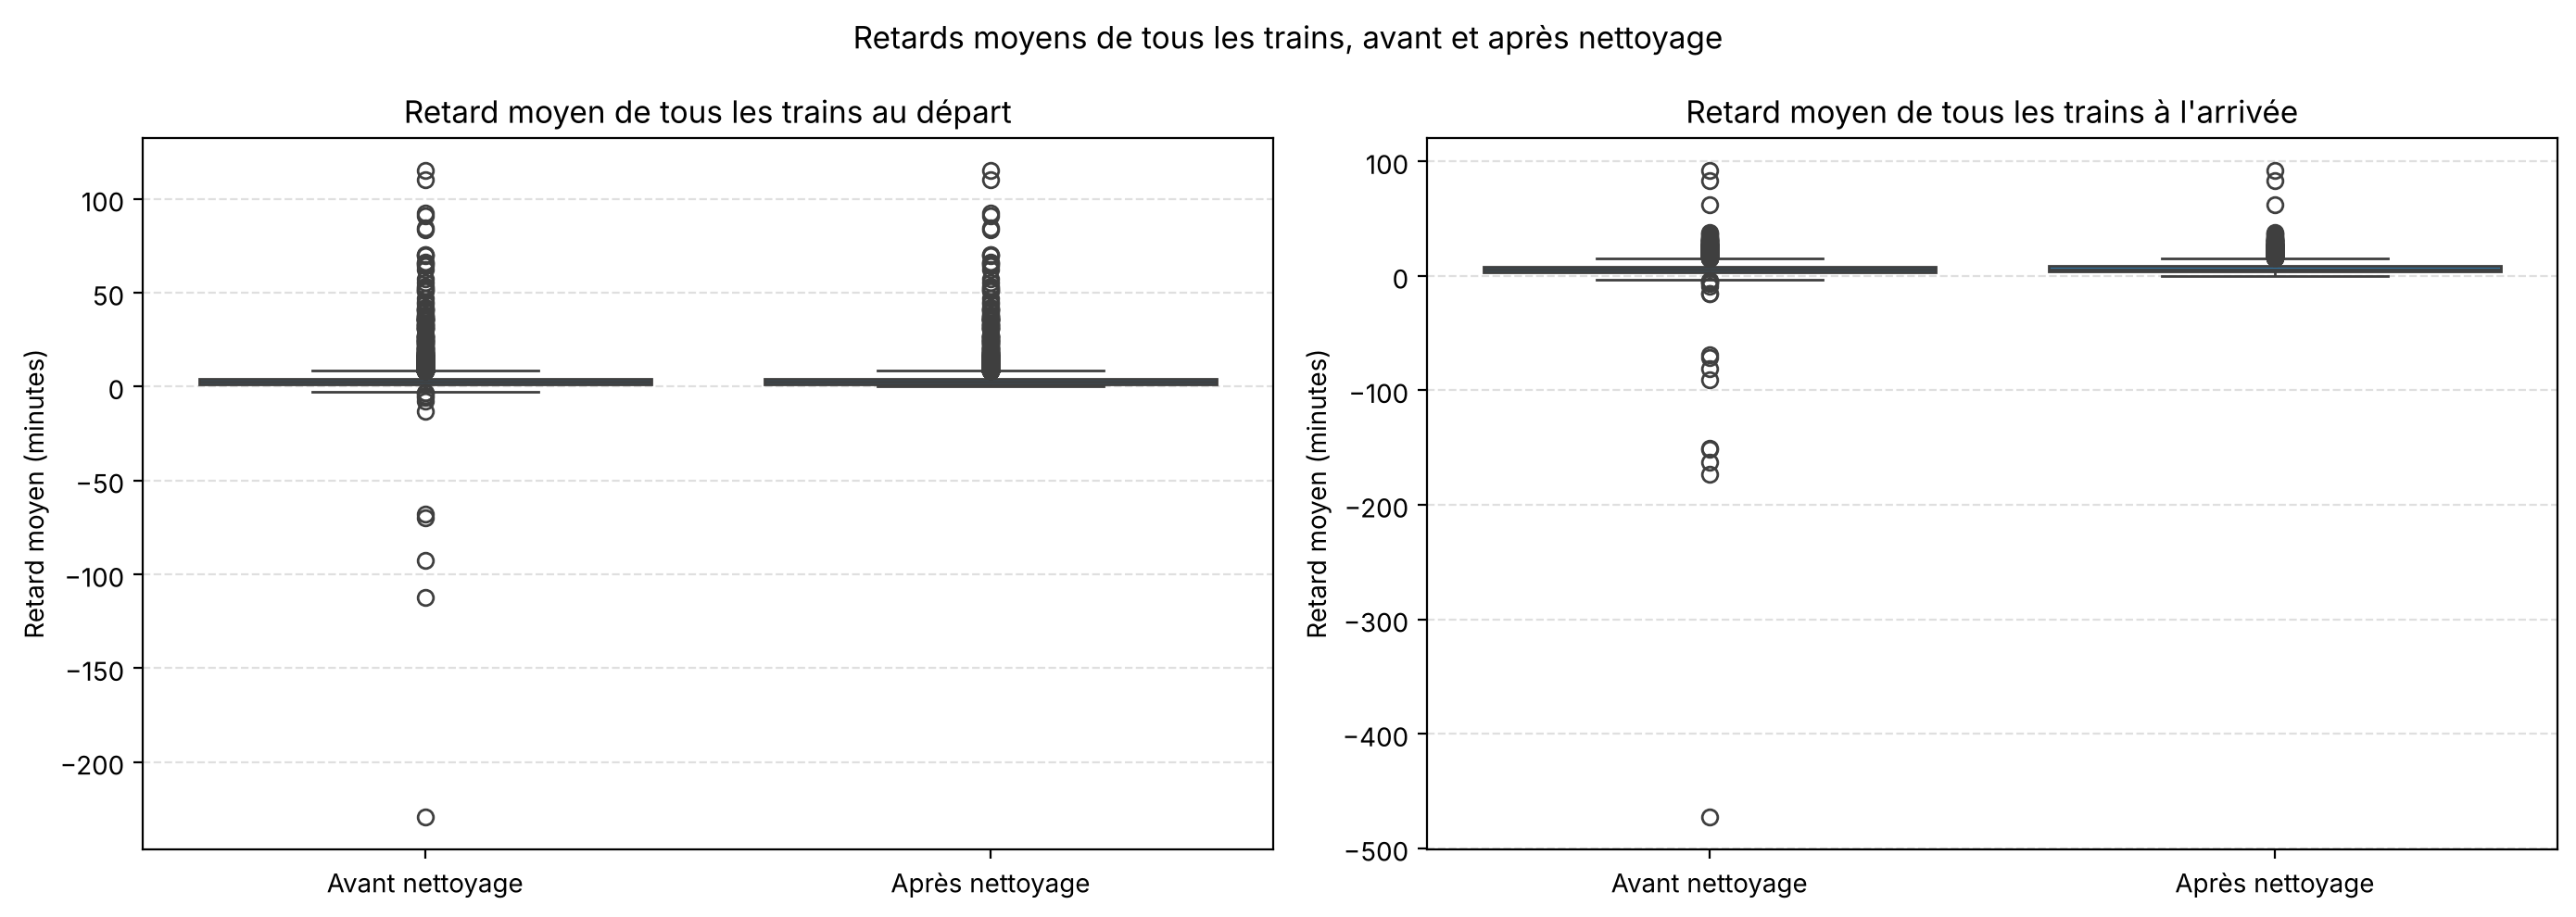

In [27]:
fig = tracer_avant_apres(
    data,
    df_propre,
    cols_retard_tous,
    "Retards moyens de tous les trains, avant et après nettoyage",
)
plt.show()